# Lesson 27: Cyclic Voltammetry

A linear sweep of voltage with time enables the simultaneous probing of current response as a function of both voltage and time. The response is affected by thermodynamics, kinetics, mass transfer, and any secondary processes. The results are therefore rich, but can be extremely complex.

Today's topics:
- Cyclic voltammetry

**Reference:**
- Ch.6 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets
import matplotlib.patches as mpatches
from IPython.display import Video, Image

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE, SINGLE, LARGE
echem.use_style()                       # course-wide graph formatting

N_ELECTRONS = 1                 # electron stoichiometry
RADIUS = 0.1                    # disc radius, cm
AREA = np.pi*RADIUS**2          # disc area, cm2
DIFF = 1e-5                     # diffusion coefficient, cm2/s (assume D_O = D_R)

CONC_O = 0.                     # oxidized species, mol/cm3
CONC_R = 1e-6                   # reduced species, mol/cm3
CONC_TOTAL = CONC_O + CONC_R

TIME = np.linspace(0.02, 2, 501)            # s
POTENTIAL = np.linspace(-0.2, 0.2, 101)     # V vs E0'


def cottrell_current(potential, t):
    '''Sampled current for THIS lesson's electrode and solution.'''
    return echem.sampled_current(potential, t, CONC_TOTAL,
                                 diff_coeff=DIFF, area=AREA, n=N_ELECTRONS)


# The shared demonstration voltammogram, loaded once for the whole lesson
demo_cv = np.genfromtxt('../Resources/data/demo_cv.csv', delimiter=',', skip_header=1)
demo_e = demo_cv[:, 0]
demo_i = demo_cv[:, 1]
FORWARD = slice(None, 1000)     # first sweep
REVERSE = slice(1000, None)     # return sweep

# 1. Review of Linear Sweep Voltammetry

We have seen several types of experiments for probing electrochemical behavior so far, including chronoamperometry, sampled current voltammetry, and linear sweep voltammetry. Before going deeper into the topic of linear sweep voltammetry, it is important to ensure that you understand how *time*, *voltage* and *current* interact with one another. The code block below displays the same 3-dimensional representation as seen in [Lesson 25](L25-SweepVoltammetry.ipynb), but slightly modified so that you can adjust a key parameter for each of the three measurement techniques and see how it traces onto the 3-dimensional data.

In [17]:
@interact(azim=widgets.FloatSlider(value=340, min=0, max=360, step=5, description='azimuth'),
          elev=widgets.FloatSlider(value=8, min=-90, max=90, step=5, description='elevation'),
          sample_time=widgets.FloatSlider(value=0.1, min=TIME.min(), max=TIME.max(),
                                          description=r'$\tau$'),
          volt_step=widgets.FloatSlider(value=0.1, min=POTENTIAL.min(), max=POTENTIAL.max(),
                                        description=r'$E_{step}$'),
          sweep_rate=widgets.FloatSlider(value=0.2, min=0.01, max=0.4, step=0.01,
                                         description=r'$\nu$'))
def plot_current_surface(volt_step, sample_time, sweep_rate, azim, elev):
    '''Why a sweep gives a PEAK: it cuts diagonally across the i(E, t) surface.

    Move the sweep rate slider and watch the green path change its angle.  A
    faster sweep reaches high potentials before the diffusion layer has grown,
    so it samples the surface where the current is still large.
    '''
    # np.meshgrid(TIME, POTENTIAL) returns the TIME grid first.  Naming matters.
    time_grid, potential_grid = np.meshgrid(TIME, POTENTIAL)
    current_grid = 1000*cottrell_current(potential_grid, time_grid)

    # where the sweep is, in time, when it reaches each potential
    sweep_time = (POTENTIAL - POTENTIAL.min())/sweep_rate
    sweep_current = np.array([
        current_grid[i, echem.nearest_index(TIME, t)] for i, t in enumerate(sweep_time)])

    fig = plt.figure(figsize=LARGE)
    ax = plt.subplot(projection='3d')
    ax.plot_wireframe(time_grid, potential_grid, current_grid,
                      rstride=2, cstride=5, color='black', alpha=0.3)

    # i vs E at one sampling time
    ax.plot(POTENTIAL, 1000*cottrell_current(POTENTIAL, sample_time),
            zs=sample_time, zdir='x', color='blue', label='sampled current voltammetry')

    # i vs t at one potential
    ax.plot(TIME, 1000*cottrell_current(volt_step, TIME),
            zs=volt_step, zdir='y', color='red', label='chronoamperometry')

    # the path the sweep actually takes
    ax.plot(sweep_time, POTENTIAL, zs=sweep_current, zdir='z', color='green',
            label='cyclic voltammetry')

    ax.set_xlabel('time /s')
    ax.set_ylabel(r"E /V vs E$^{0'}$")
    ax.set_zlabel('i /mA')
    ax.view_init(elev, azim)
    ax.set_xlim(TIME.min(), TIME.max())
    ax.set_ylim(POTENTIAL.min(), POTENTIAL.max())
    fig.legend(fontsize=6)

interactive(children=(FloatSlider(value=0.1, description='$E_{step}$', max=0.2, min=-0.2), FloatSlider(value=0…

The diagram above hopefully makes it possible for you to visualize exactly why we obtain a peak shape in a linear sweep experiment: we are perturbing the system in two dimensions ( $E$ and $t$ ) while monitoring a third dimension ( $i$ ). The increasing voltage causes the currents to go up, but the increasing time causes growth of a diffusion layer, which causes currents to go down. The peak shape is the direct result of competing processes.

# 2. Cyclic Voltammetry

Cyclic voltammetry is simply linear sweep voltammetry that is performed with a secondary reverse sweep:

E_p,a - E_1/2   =  20.0 mV
E_p,a - E_p,c   =  40.1 mV
|i_p,a / i_p,c| =  1.08


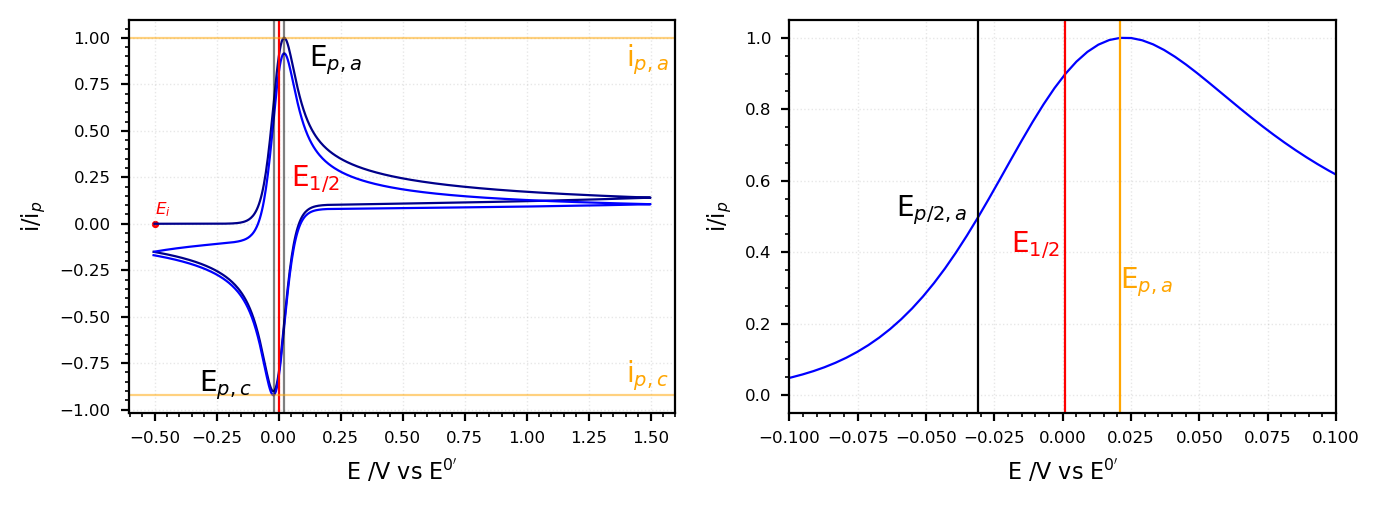

In [3]:
# The landmarks of a cyclic voltammogram.  All of them are located FROM THE DATA.
i_max = int(np.argmax(demo_i))
i_min = int(np.argmin(demo_i))
e_pa = demo_e[i_max]                        # anodic peak
e_pc = demo_e[i_min]                        # cathodic peak
e_half = (e_pa + e_pc)/2                    # half wave potential
e_pa2 = demo_e[echem.nearest_index(demo_i[:i_max], demo_i.max()/2)]   # half peak

fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)
for ax in [ax1, ax2]:
    ax.set_xlabel(r"E /V vs E$^{0'}$")
    ax.set_ylabel(r'i/i$_p$')

ax1.scatter(-0.5, 0, color='red')
ax1.plot(demo_e[FORWARD], demo_i[FORWARD], 'darkblue')
ax1.plot(demo_e[REVERSE], demo_i[REVERSE], 'blue')

ax1.annotate(r'$E_i$', (-0.5, 0.05), fontsize=6, color='red')
ax1.axvline(e_half, linestyle='-', color='red', label=r'E$_{1/2}$')
ax1.axvline(e_pa, color='black', alpha=0.5)
ax1.axvline(e_pc, color='black', alpha=0.5)
ax1.annotate(r'E$_{p,a}$', (e_pa + 0.1, 0.85))
ax1.annotate(r'E$_{p,c}$', (e_pc - 0.3, -0.9))
ax1.annotate(r'E$_{1/2}$', (e_half + 0.05, 0.2), color='red')

ax1.axhline(demo_i.max(), color='orange', alpha=0.5)
ax1.annotate(r'i$_{p,a}$', (1.4, 0.85), color='orange')
ax1.axhline(demo_i.min(), color='orange', alpha=0.5)
ax1.annotate(r'i$_{p,c}$', (1.4, -0.85), color='orange')

# Enlarged view of the anodic peak
ax2.plot(demo_e[0:250], demo_i[0:250], 'b')
ax2.axvline(e_pa, color='orange')
ax2.annotate(r'E$_{p,a}$', (e_pa, 0.3), color='orange')
ax2.axvline(e_half, linestyle='-', color='red')
ax2.annotate(r'E$_{1/2}$', (e_half - 0.02, 0.4), color='red')
ax2.axvline(e_pa2, color='black')
ax2.annotate(r'E$_{p/2,a}$', (e_pa2 - 0.03, 0.5), color='black')
ax2.set_xlim(-0.1, 0.1)

fig.tight_layout()
fig.savefig('../Workspace/CV_markedup.png')

# The three diagnostic numbers.  Compare them with the values the markdown
# above predicts for a fully reversible one-electron couple, and note that this
# demonstration data set is sampled on a fairly coarse potential grid.
print(f'E_p,a - E_1/2   = {1000*(e_pa - e_half):5.1f} mV')
print(f'E_p,a - E_p,c   = {1000*(e_pa - e_pc):5.1f} mV')
print(f'|i_p,a / i_p,c| = {abs(demo_i.max()/demo_i.min()):5.2f}')

The reverse sweep introduces a secondary peak in current that will have a particular shape and similar numeric parameters that can be extracted. New terms can therefore be defined to capture *electrochemically reversible* behavior:

\begin{equation}
\large |E_p - E_{1/2}| = \frac{28.5 mV}{n}
\end{equation} 

\begin{equation}
\large |E_{p/2} - E_{1/2}| = \frac{28.0 mV}{n}
\end{equation} 

\begin{equation}
\large \frac{i_{p,a}}{i_{p,c}} = 1.0
\end{equation} 

These are written as magnitudes because the sign depends on sweep direction: on a **cathodic** sweep $E_p$ lies below $E_{1/2}$ and $E_{p/2}$ above it, while on an **anodic** sweep the two are reversed. $E_p$ and $E_{p/2}$ always straddle $E_{1/2}$ , which is why their separation is the sum, 56.5 mV/ $n$ .

All considerations regarding *current*, *time* and *voltage* that were introduced in [Lesson 25](L25-SweepVoltammetry.ipynb) apply here. The diffusion layer is never given a chance to rest and reset itself in these experiments. It is therefore critical that all of these variables be considered when interpreting the data observed. The most prominent effect of this is seen in the reverse sweep, and on subsequent forward sweeps:

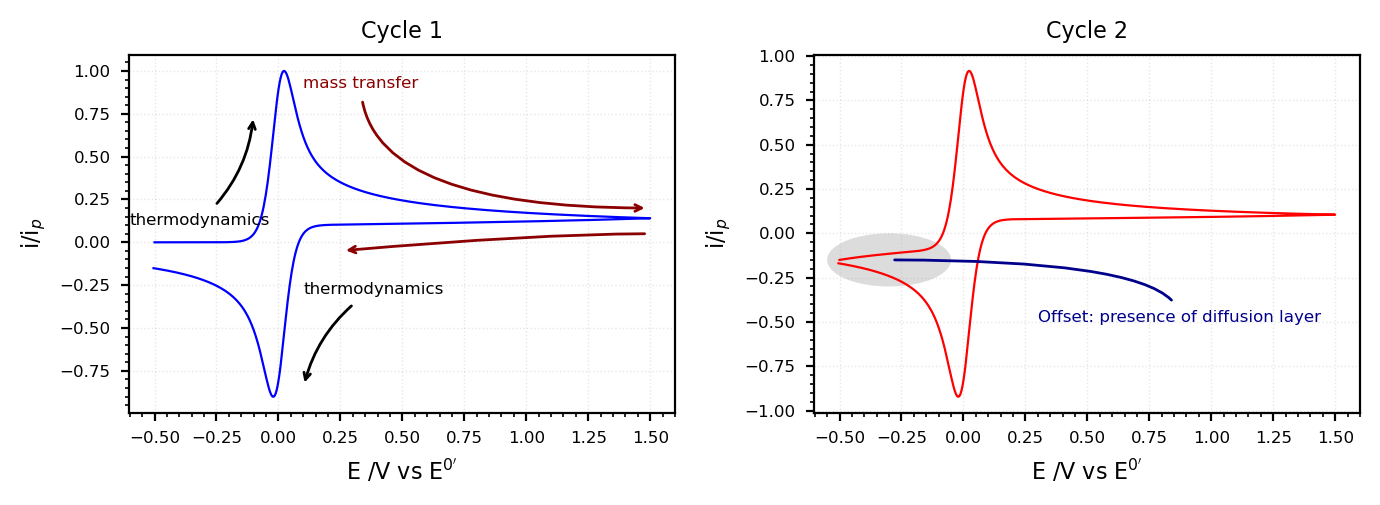

In [4]:
fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)
for ax in [ax1, ax2]:
    ax.set_xlabel(r"E /V vs E$^{0'}$")
    ax.set_ylabel(r'i/i$_p$')

ax1.plot(demo_e[FORWARD], demo_i[FORWARD], 'b')
ax1.set_title('Cycle 1')
ax1.annotate('thermodynamics',
             xy=(-0.1, 0.75), xycoords='data',
             xytext=(-0.6, 0.1), textcoords='data', fontsize=6,
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.2'))
ax1.annotate('thermodynamics',
             xy=(0.1, -0.85), xycoords='data',
             xytext=(0.1, -0.3), textcoords='data', fontsize=6,
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.2'))
ax1.annotate('mass transfer', color='darkred',
             xy=(1.5, 0.2), xycoords='data',
             xytext=(0.1, 0.9), textcoords='data', fontsize=6,
             arrowprops=dict(arrowstyle='->', color='darkred',
                             connectionstyle='angle3,angleA=90,angleB=0'))
ax1.annotate('', color='darkred',
             xy=(0.25, -0.05), xycoords='data',
             xytext=(1.5, 0.05), textcoords='data', fontsize=6,
             arrowprops=dict(arrowstyle='->', color='darkred',
                             connectionstyle='angle3,angleA=0,angleB=5'))

ax2.plot(demo_e[REVERSE], demo_i[REVERSE], 'r')
ax2.set_title('Cycle 2')
ax2.add_artist(mpatches.Ellipse((-0.3, -0.15), 0.5, 0.3, angle=0, alpha=0.2))
ax2.annotate('Offset: presence of diffusion layer', color='darkblue',
             xy=(-0.3, -0.15), xycoords='data',
             xytext=(0.3, -0.5), textcoords='data', fontsize=6,
             arrowprops=dict(arrowstyle='-', color='darkblue',
                             connectionstyle='angle3,angleA=90,angleB=0'))

fig.savefig('../Workspace/twocycles.png')

# 3. Diffusion Layers

A new section will be started for this concept because it is critically important. Much of the characteristic behavior that is analyzed by cyclic voltammetry is dictated by mass transfer - understanding how diffusion layers form and how they react to perturbations is central to mastering voltammetry.

In [5]:
Video('../Resources/images/CVa.mp4')

Such a synchronized perspective makes a number of features more apparent and easy to understand. For example, reversal of potential sweep direction effectively generates a wave of disruption within the solution. The reverse sweep (cathodic in this case) is acting directly on this wave, causing the wave to dissipate by diffusing in both directions. This is why the reverse peak appears smaller in absolute magnitude than the forward peak when measured from the zero-current axis -- recovering the true ratio $i_{p,a}/i_{p,c} = 1$ requires measuring from a properly extrapolated baseline, as described below.

Concentration profile plots as a function of location in the voltammogram capture these key features.

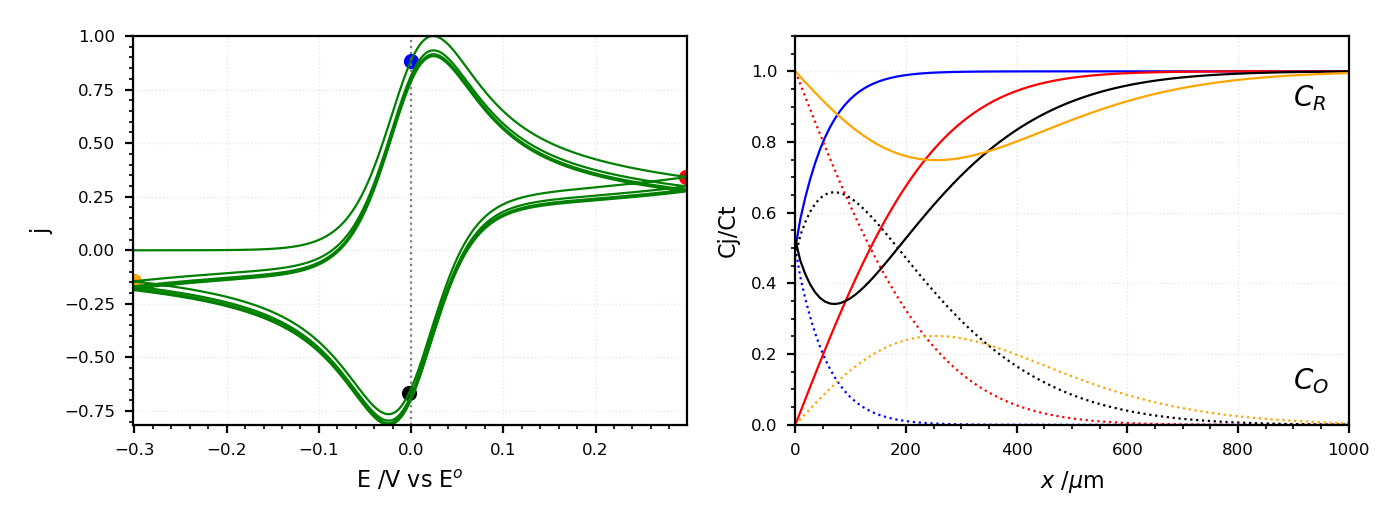

In [6]:
Image('../Resources/images/CV-diffusion.png')

Any software you may use to collect data likely has a peak-fit function that you use to extract parameters. As a user, you are responsible for judging the boundaries for the algorithm used in the fitting, and for verifying the quality of the results. 

If we circle back to the equations that describe expected peak shape, it is now apparent that the diffusion layers must be considered to properly extract relevant parameters:

\begin{equation}
\large i_p = 2.69x10^5 n^\frac{3}{2} A \sqrt{D_i \nu} C_i
\end{equation} 
\begin{equation}
\large |E_p - E_{1/2}| = \frac{28.5 mV}{n}
\end{equation} 
\begin{equation}
\large |E_{p/2} - E_{1/2}| = \frac{28.0 mV}{n}
\end{equation} 
\begin{equation}
\large |E_p - E_{p/2}| = \frac{56.5 mV}{n}
\end{equation} 
\begin{equation}
\large \frac{i_{p,a}}{i_{p,c}} = 1.0
\end{equation} 


The effect of the diffusion layer can be approximated by extrapolation of the baseline. 

<div class="alert alert-block alert-success">
 <b> Defining Baselines:</b>
 <br>
- If the baseline is curving significantly you should use the Cottrell Equation as a baseline<br> 
- If the current has reached a point of slow decay, you can approximate the baseline using a linear slope
</div>

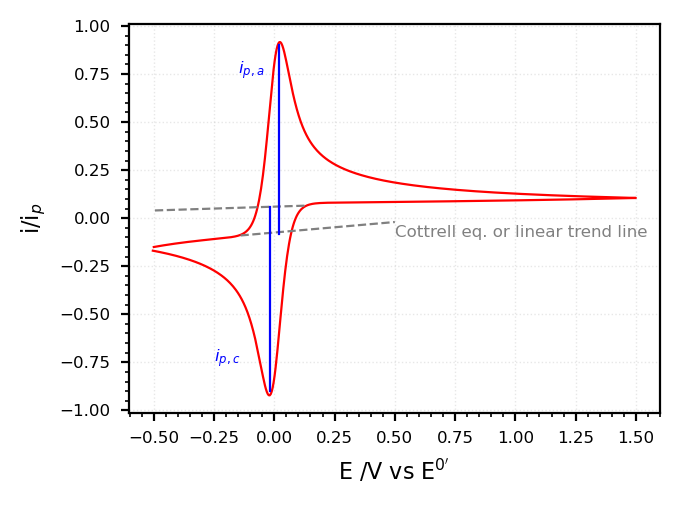

In [7]:
# Choosing a baseline is a judgement call, and it is YOUR judgement, not the
# software's.  e_pa and e_pc were located from the data in the cell above.
fig = plt.figure(figsize=SINGLE)
ax1 = plt.subplot()
ax1.set_xlabel(r"E /V vs E$^{0'}$")
ax1.set_ylabel(r'i/i$_p$')

ax1.plot(demo_e[REVERSE], demo_i[REVERSE], 'r')
ax1.annotate('Cottrell eq. or linear trend line', (0.5, -0.1), color='gray', fontsize=6)
ax1.plot([0.125, -0.5], [0.065, 0.04], linestyle='--', color='gray')
ax1.plot([-0.14, 0.5], [-0.09, -0.02], linestyle='--', color='gray')
ax1.plot([e_pa, e_pa], [0.9, -0.08], linestyle='-', color='blue')
ax1.annotate(r'$i_{p,a}$', (-0.15, 0.75), color='blue', fontsize=6)
ax1.plot([e_pc, e_pc], [0.06, -.9], linestyle='-', color='blue')
ax1.annotate(r'$i_{p,c}$', (-0.25, -0.75), color='blue', fontsize=6)

fig.savefig('../Workspace/CVbaselines.png')

The specific behavior you observe will depend on your experimental settings. Some examples are provided below for variations in $E_i$ and $E_s$ .

Extension of the voltage window stabilizes the observed results by producing a diffusion layer that approximates the bulk concentration of the redox active species. Remember that the extent of the diffusion layer depends on time; the scan rate used will affect this behavior.

<div class="alert alert-block alert-success">
 <b>Experimental Necessity:</b><br>
- Explore scan rate, $E_i$ and $E_s$ when studying new systems to ensure you gain a complete perspective on the behavior. This will help you to obtain the best quality results
</div>

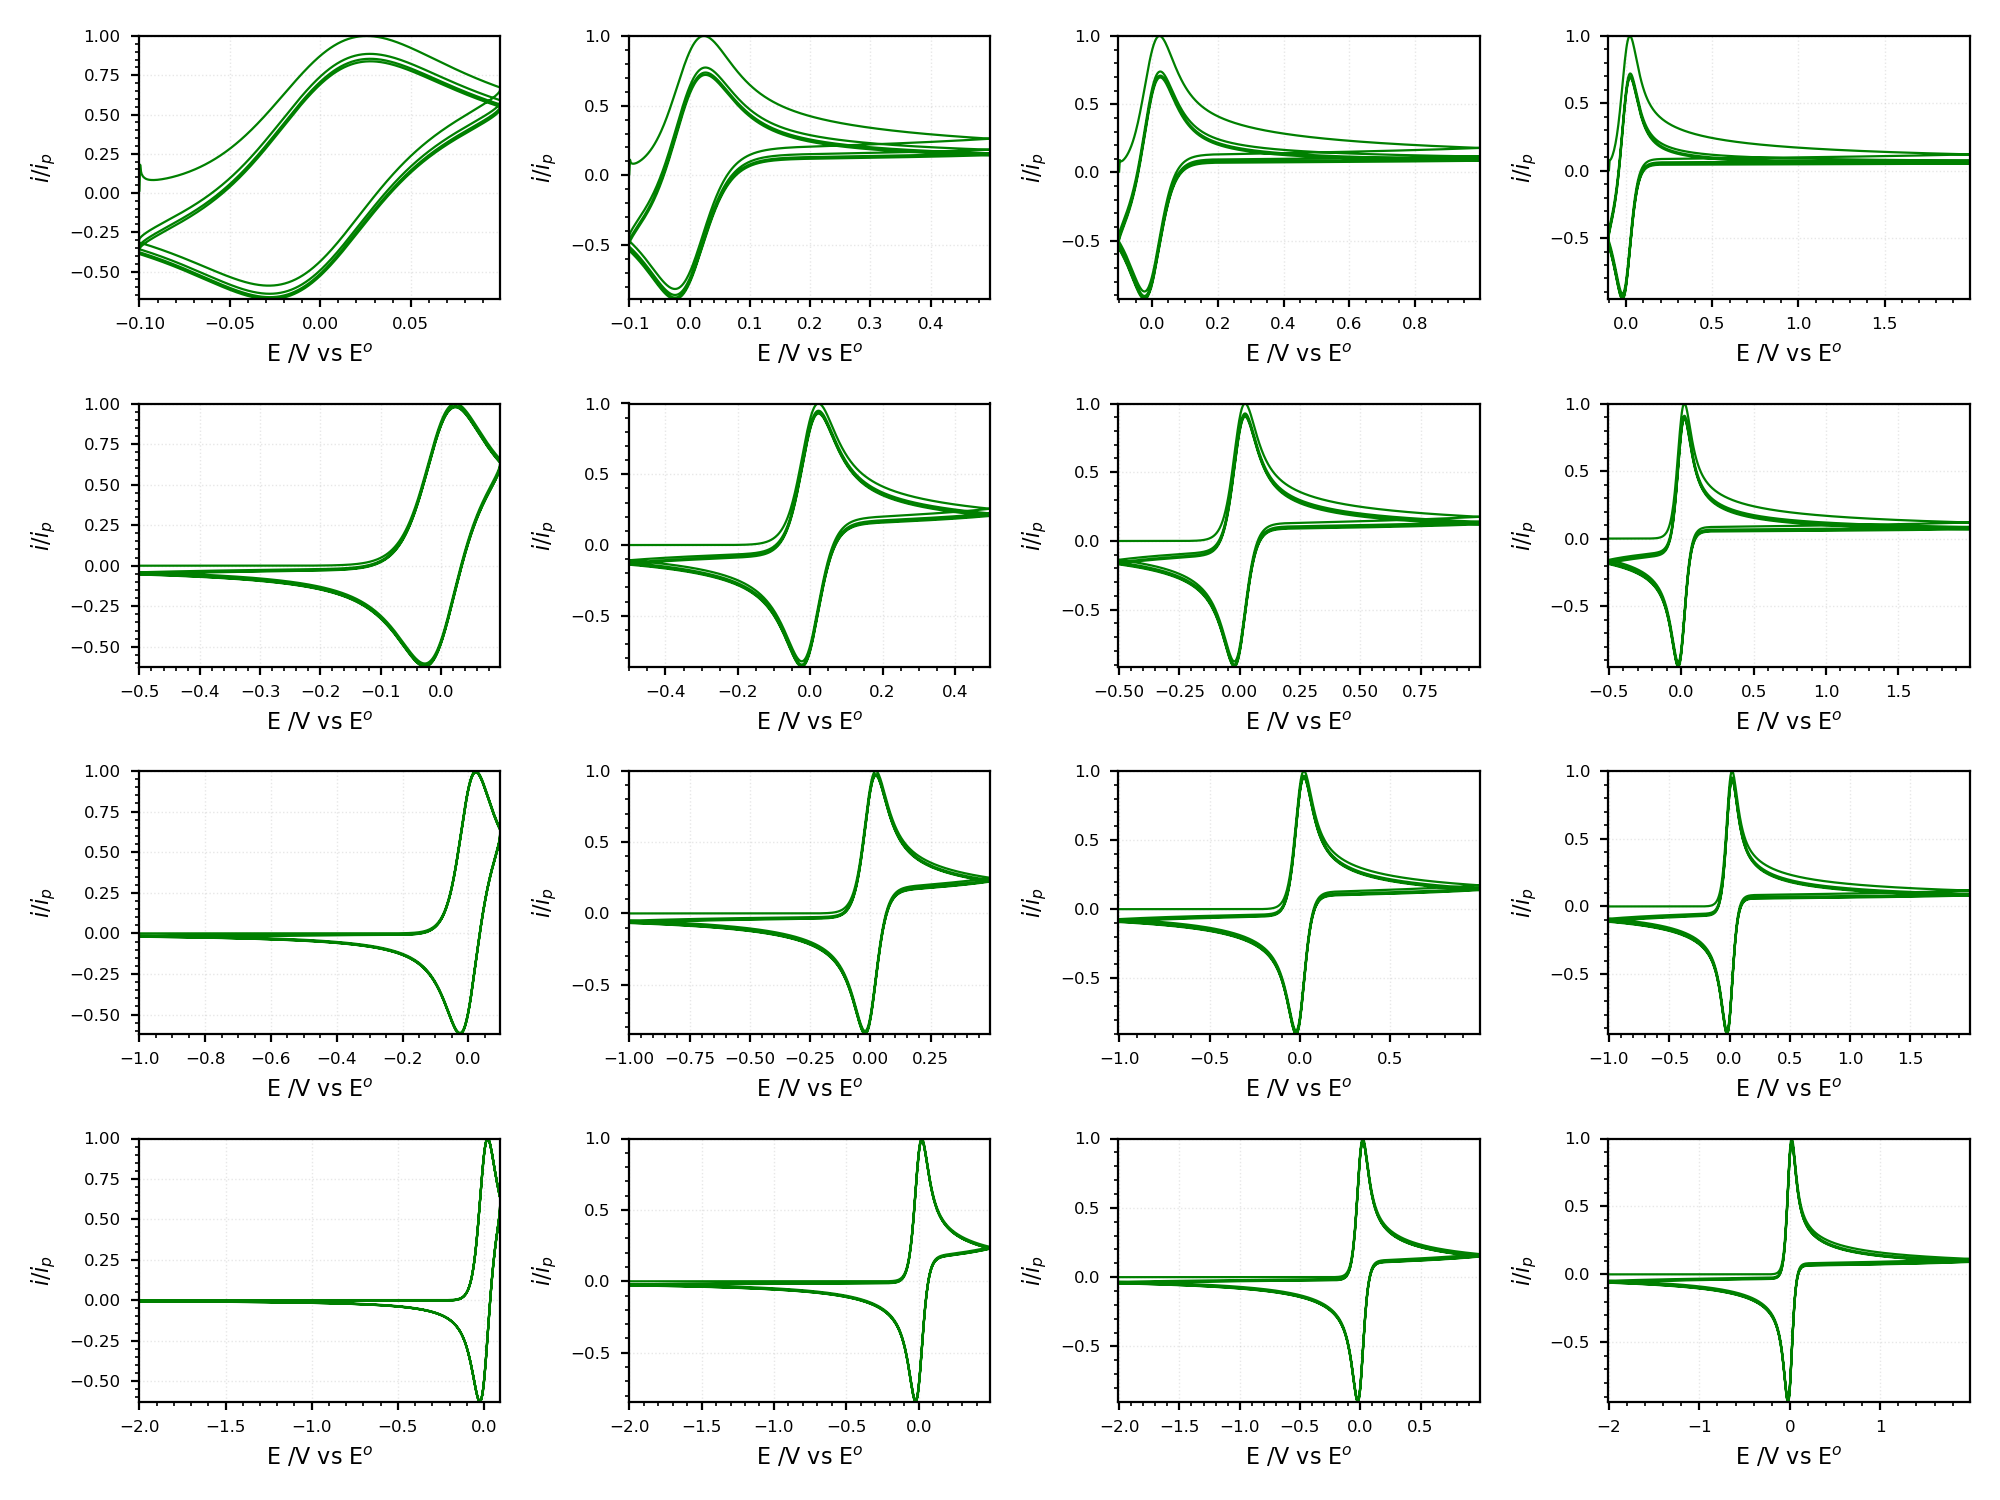

In [8]:
Image('../Resources/images/CV-variedStartSwitch.png')

Using an $E_i$ that is far from the equilibrium of the redox species in the system will result in current flow at the onset of the experiment. If the reaction is irreversible, or you are working with thin film coatings, this current flow can completely change the behavior that you observe. 

See Figure 6.5.2 in Bard & Faulkner's textbook.

<div class="alert alert-block alert-info">
<b>Activity:</b> Sketch concentration profiles at selected points for the above figures to explain the changes in observed behavior.
</div>

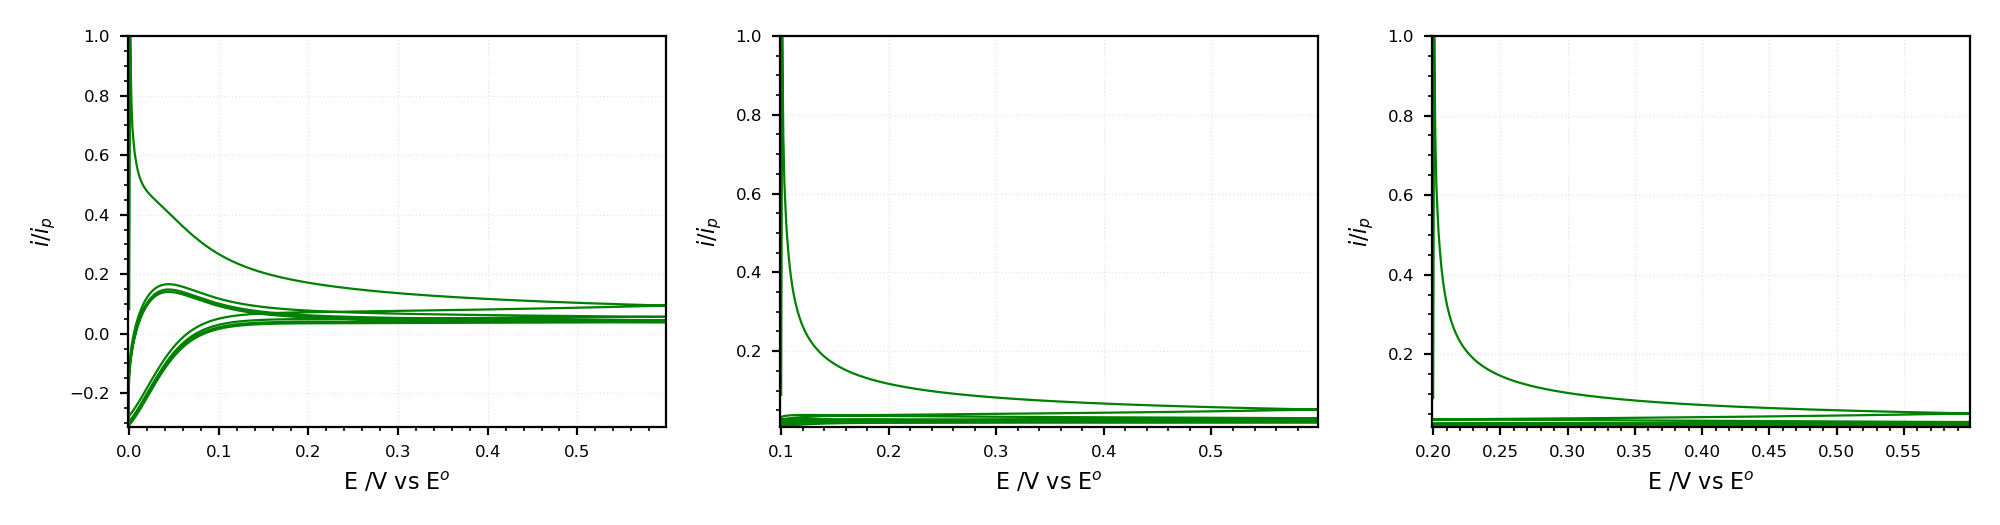

In [9]:
Image('../Resources/images/CV-badStart.png')

The equilibrium of the system can be determined by measuring the **open circuit potential** ( $E_{OC}$ ). 
 
There is no direct harm in using a different $E_i$ if the reaction system is reversible and stable at the potential. For example:

- In the situation two cells above, $C_R/C_T = 1.0$ and $E_i$ << $E^{0'}$ . 
- In the situation below, $C_R/C_T = 1.0$ and $E_i$ >> $E^{0'}$ . 

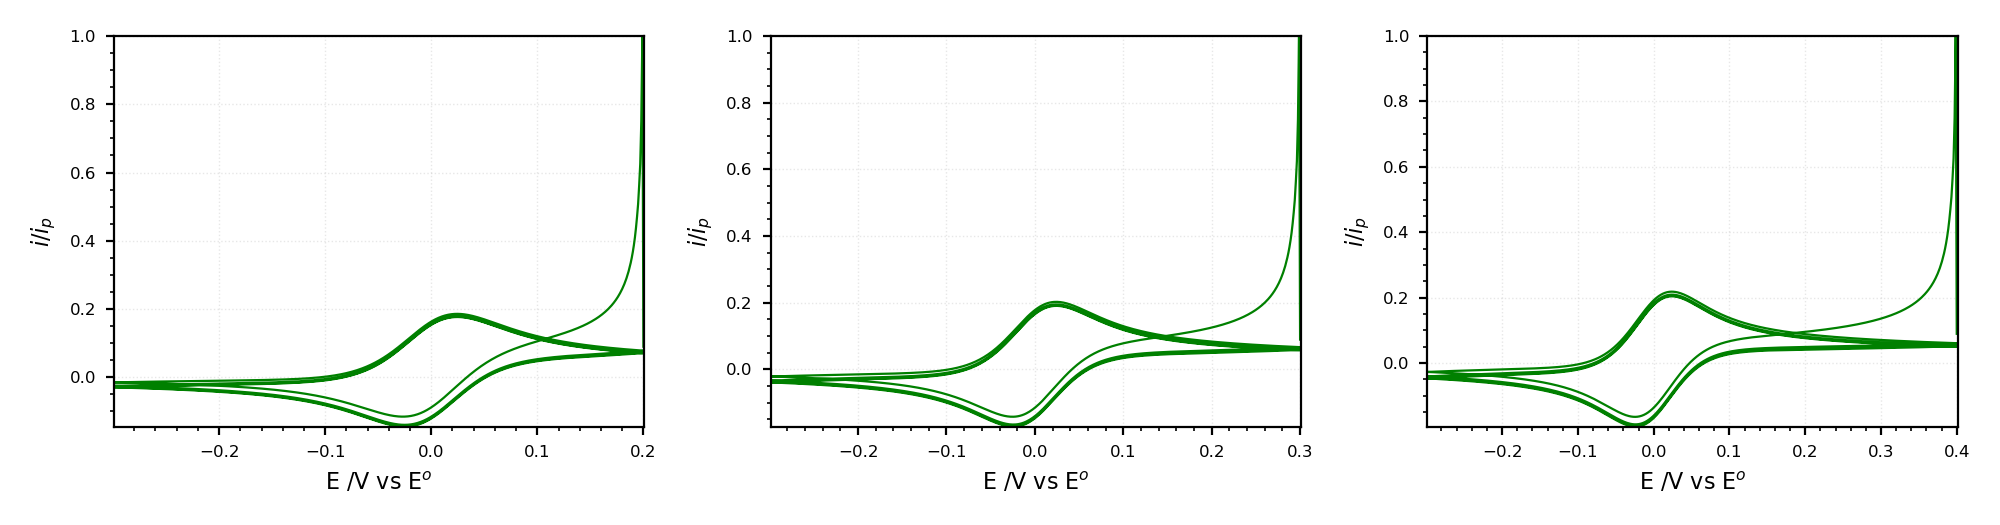

In [10]:
Image('../Resources/images/CV-oppositeStart.png')

<div class="alert alert-block alert-success">
- $E_i$ should be chosen to be $E_{OC}$ unless you are familiar with the reaction system being studied and have good reason to do otherwise 
</div>

# 4. Influence of Resistance and Kinetics



#### Uncompensated Resistance

**Uncompensated resistance** causes voltammetric peaks to distort and shift to more extreme voltages: anodic peaks seem to move positive and cathodic peaks negative. This apparent shift is accompanied by a decrease in peak height. Each of these effects become more extreme at higher scan rates.

<img src='../Resources/images/resistance.png' width=30%>

<div class="alert alert-block alert-info">
<b>Activity:</b> What causes resistance to induce these effects on the observed behavior? Can you reproduce the effects of resistance in the figure below?
</div>

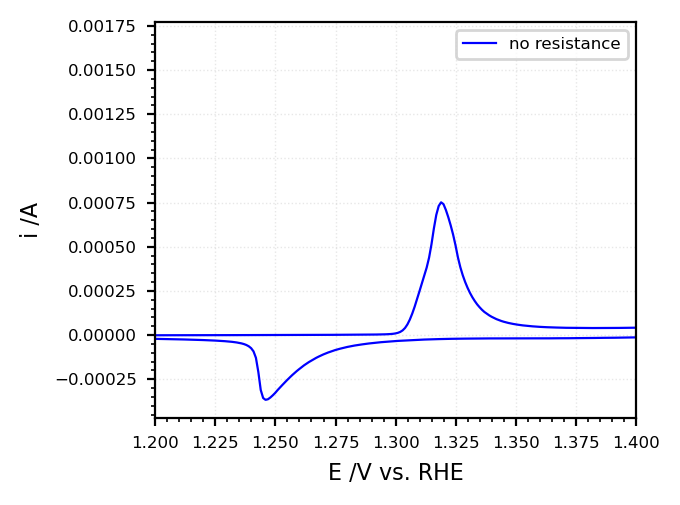

In [11]:
# A real Ni(OH)2 voltammogram, before any resistance is added.
# Rows 0 to 900 are the first cycle.
ni_cv = np.genfromtxt('../Resources/data/CV-NiHydroxide.csv', delimiter=',', skip_header=1)
FIRST_CYCLE = slice(None, 900)
ni_e = ni_cv[FIRST_CYCLE, 0]
ni_i = ni_cv[FIRST_CYCLE, 1]

fig = plt.figure(figsize=SINGLE)
ax1 = plt.subplot()
ax1.set_xlabel(r'E /V vs. RHE')
ax1.set_ylabel(r'i /A')
ax1.set_xlim(1.2, 1.4)
ax1.plot(ni_e, ni_i, 'b', label='no resistance')
ax1.legend(fontsize=6)

fig.savefig('../Workspace/resistance.png')

#### Electron Transfer Kinetics

All aspects of kinetics can influence the observed behavior. The variation of $\alpha$ distorts the relative symmetry of the peaks (note the convention used!):

- **1**: $\alpha=0.5$ 
- **2**: $\alpha=0.3$ 

<img src='../Resources/images/cv_alpha.png' width=20%>

Discussions of inherent kinetics, measured by the standard rate constant $k^0$ , are more complex. One should note however, that **decreasing $k^0$ yields changes that are qualitatively similar to those due to uncompensated resistance**. That is, the peaks decrease in intensity and shift to more extreme voltages. A full discussion on how reaction kinetics affect peak shapes is well beyond the level of this course (see Bard & Faulkner Section 6.4 for a brief introduction if interested; or *Elements of Molecular and Biomolecular Electrochemistry* by Saveant and Costentin for a much more in-depth discussion). We will, however, establish a basic understanding of what to expect.

A dimensionless parameter can be defined to link kinetics, mass transfer and scan rate:

$
\large \Lambda = \frac{k^0}{\sqrt{D_O^{1-\alpha}D_R^\alpha f\nu}}
$

A new function ( $K$ ) is defined that employs this dimensionless parameter:

$
\large i_p = i_{p,reversible}K(\Lambda, \alpha)
$

When the standard rate constant for electron transfer kinetics is large **compared to the rate at which the potential is swept** -- that is, when $\Lambda$ is large -- $K = 1$ and the Randles-Sevcik equation is obeyed. This function becomes less than 1 when $\Lambda < 10$ , however, yielding a decrease in peak current:

<img src='../Resources/images/cv_kinetics1.png' width=20%>

The beauty of dimensionless parameters is that behavior can be completely generalized. The relationship between $\Lambda$ and $K(\Lambda, \alpha)$ is:

- $\alpha$ parameter labeled along side

<img src='../Resources/images/cv_lambda.png' width=20%>

The generalized linear sweep behavior is then:

- (I) $\Lambda$ = 10
- (II) $\Lambda$ = 1
- (III) $\Lambda$ = 0.1
- (IV) $\Lambda$ = 0.01

<img src='../Resources/images/cv_kinetics.png' width=30%>

One interesting outcome of this is that the peak current becomes decoupled from scan rate for quasi-reversible reactions. This feature can be readily seen in the figure above: an increase in scan rate will cause a decrease in $\Lambda$ , yielding the behavior seen between curves (I)-(IV). In addition to this, the shape and location of the peak also exhibit systematic changes that can be described through dimensionless parameters. The separation between anodic and cathodic peaks, for example, can be linked to $\psi$ , which is related to $\Lambda$ :

<img src='../Resources/images/kinetics_table.png' width=20%>


It has been suggested that the three kinetic regions be described as:

- Reversible (nernstian): $\Lambda \geq 15$ ; $k^0 \geq 0.3 \nu^{1/2}$ cm/s
- Quasireversible: $15 \geq \Lambda \geq 10^{-2(1+\alpha)}$ ; $0.3\nu^{1/2} \geq k^0 \geq 2 \times 10^{-5}\nu^{1/2}$ cm/s
- Totally irreversible: $\Lambda \leq 10^{-2(1+\alpha)}$ ; $k^0 \leq 2 \times 10^{-5}\nu^{1/2}$ cm/s

# 5. Multiple Redox Processes

Currents arising from different processes are additive in electrochemical experiments; if one redox process does not directly alter a secondary one, the co-existence of multiple redox processes can be handled by defining a suitable baseline and handling all processes independently.

In [12]:
Video('../Resources/images/CV-threeRedox.mp4')

Inspection of concentration profiles for each individual redox species demonstrates that each individual process follows exactly the same pattern, differing from each other only in *time*. This behavior will, of course, change if the electron transfer reactions share an intermediate species.

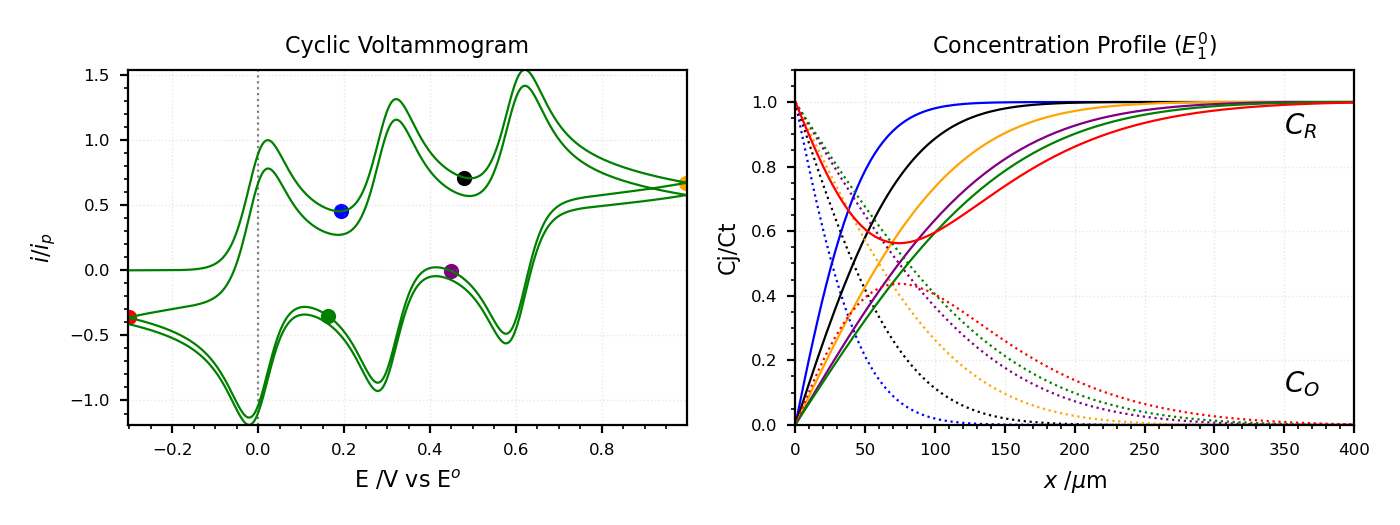

In [13]:
Image('../Resources/images/CV-multiple.png')

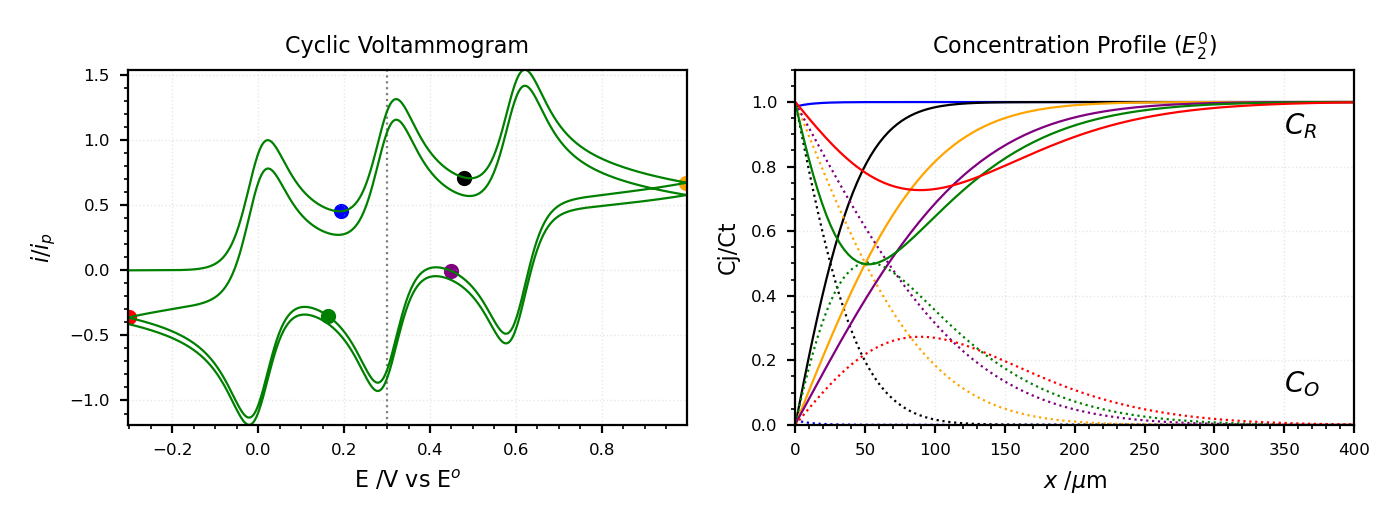

In [14]:
Image('../Resources/images/CV-multipleB.png')

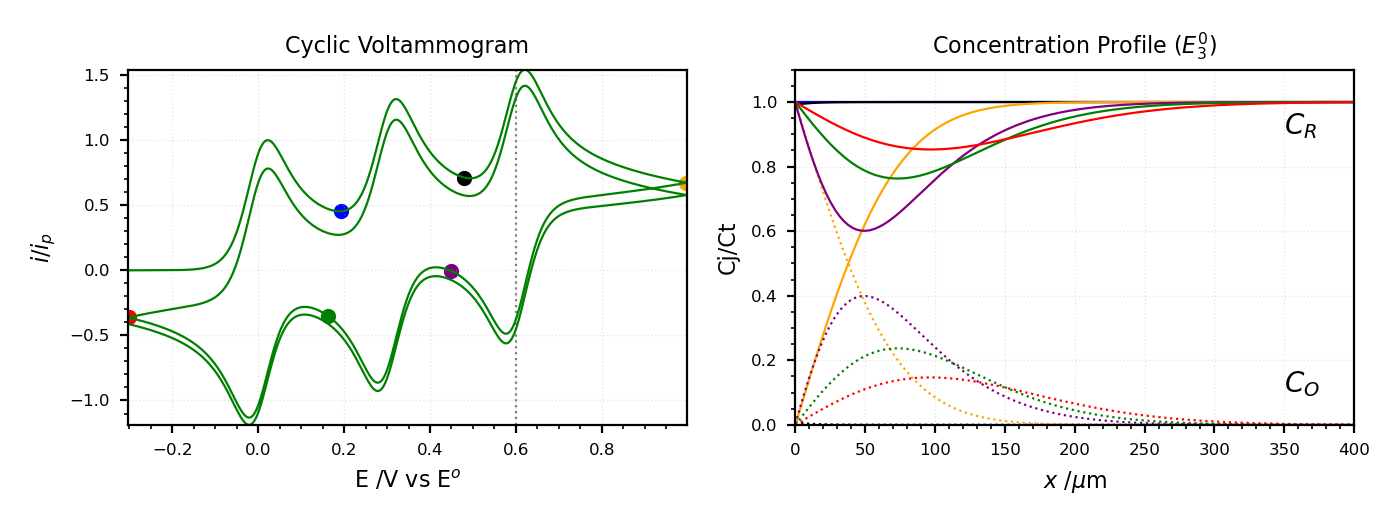

In [15]:
Image('../Resources/images/CV-multipleC.png')

In such a situation it is straightforward to select an appropriate baseline for each individual process:

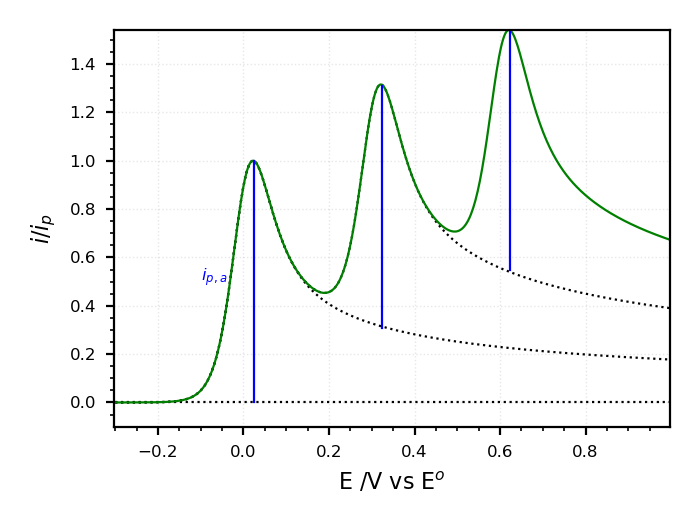

In [16]:
Image('../Resources/images/CV-multipleBaselines.png')

<div class="alert alert-block alert-success">
- You can, and should, rely on fundamentals to guide your thinking as the complexity of your reaction system increases: <b>thermodynamics, kinetics and mass transfer</b>!
</div>

---
# (Optional) Further Reading

All figures above were created through simulation of voltammetric behavior. For those interested, numerous excellent resources are available to assist you in learning to simulate cyclic voltammograms (Warning: requires dedication!). Such simulations enable visualization of various aspects of the reaction system, such as the diffusion layer.

For example, see:
*Understanding Voltammetry: Simulation Of Electrode Processes* by Richard Compton, Eduardo Laborda and Kristopher R Ward.